## Siting and Sizing Battery Storage on the PJM 5-Bus Network: Multi-Period DC-OPF
Where should a battery go on a congested network, and how big should it be? This notebook answers both questions on the PJM 5-bus case with a 24-hour multi-period DC-OPF: it solves the model for every candidate bus and a sweep of battery sizes, and compares the daily generation-cost savings. It then uses the model's dual variables (nodal prices) to explain what the battery does to congestion on Branch 6. It extends the single-period DC-OPF notebook [01_dcopf_pyomo.ipynb](https://github.com/vjkhtw/pjm5-opf/blob/main/notebooks/01_dcopf_pyomo.ipynb), which supplies the network and cost data.

**Contents**
* Summary of Findings
* Setup and Data
* Model
* Checks
* Reading Duals in a Multi-Period Model
* 1. Siting at a Fixed Size
* 2. Sizing
* 3. Battery Operation at Bus 4
* Conclusion


## Summary of Findings

The no-battery operating cost over the 24-hour profile is *\$357,972.81*. All savings are daily generation-cost reductions relative to this baseline.

* **Location matters most for small batteries.** At 50 MW / 200 MWh, a battery at Bus 4 saves *\$1,071.79* per day (0.30%), Bus 3 *\$875.21*, Bus 2 *\$803.20*, Bus 5 *\$348.22* and Bus 1 *\$38.24*. The ranking follows how far the no-battery nodal price swings over the day at each bus (*\$25*/MWh at Bus 4, *\$2*/MWh at Bus 1). Bus 4 is on the load side of the congested Branch 6, and Bus 5 is behind it.
* **Savings level off with energy capacity.** At Bus 4 with a 4-hour battery, savings stop growing at about 300 MWh (*\$1,314* per day). A 200 MWh battery captures 82% of that, a 250 MWh battery 91% and a 275 MWh battery 95%. These results assume each battery starts and ends the day at 50% SOC; with 10% the plateau is reached at 250 MWh (Section 2.4).
* **Power matters when it limits charging.** At 200 MWh, raising the power rating above 50 MW adds nothing, while a lower rating (25 MW / 8 h) saves 3.4% less because the battery cannot charge fast enough in the low-cost hours.
* **Larger batteries are used less.** Equivalent full cycles per day fall from 0.50 at 100 MWh to 0.29 at 500 MWh.
* **The battery does not relieve Branch 6.** The line is at its limit in all 24 hours with the battery, against 21 without it. Its shadow price is essentially unchanged at the peak (about *\$62*/MWh) and rises from zero to about *\$45*/MWh in hours 2 to 4, because overnight charging at Bus 4 uses up the line's slack (Section 3.2).

These are operating-cost savings on a synthetic load profile and a lossless DC model, not an investment case.

## Setup and Data
**Question:** How does battery location and size affect generation cost on the PJM 5-bus network?

**Method:** A 24-hour multi-period DC-OPF is built in Pyomo and solved with HiGHS. The no-battery case provides the baseline. Battery cases are then solved for different buses and sizes, and their total generation costs are compared. This repeated solving while varying one parameter at a time is called a *parameter sweep*. The dual variables of the solved model give nodal prices (LMPs) and the Branch 6 shadow price, which Section 3.2 uses to explain what the battery does to congestion.

**Network and generators:** The test system is the 5-bus PJM case from the [IEEE PES Power Grid Library](https://github.com/power-grid-lib/pglib-opf/blob/master/pglib_opf_case5_pjm.m) (`pglib_opf_case5_pjm`): 5 buses, 5 generators and 6 transmission lines. The network, generator costs and limits are the same as in the single-period DC-OPF notebook ([01_dcopf_pyomo.ipynb](https://github.com/vjkhtw/pjm5-opf/blob/main/notebooks/01_dcopf_pyomo.ipynb)). Generator and branch data are tabulated below the data cell.

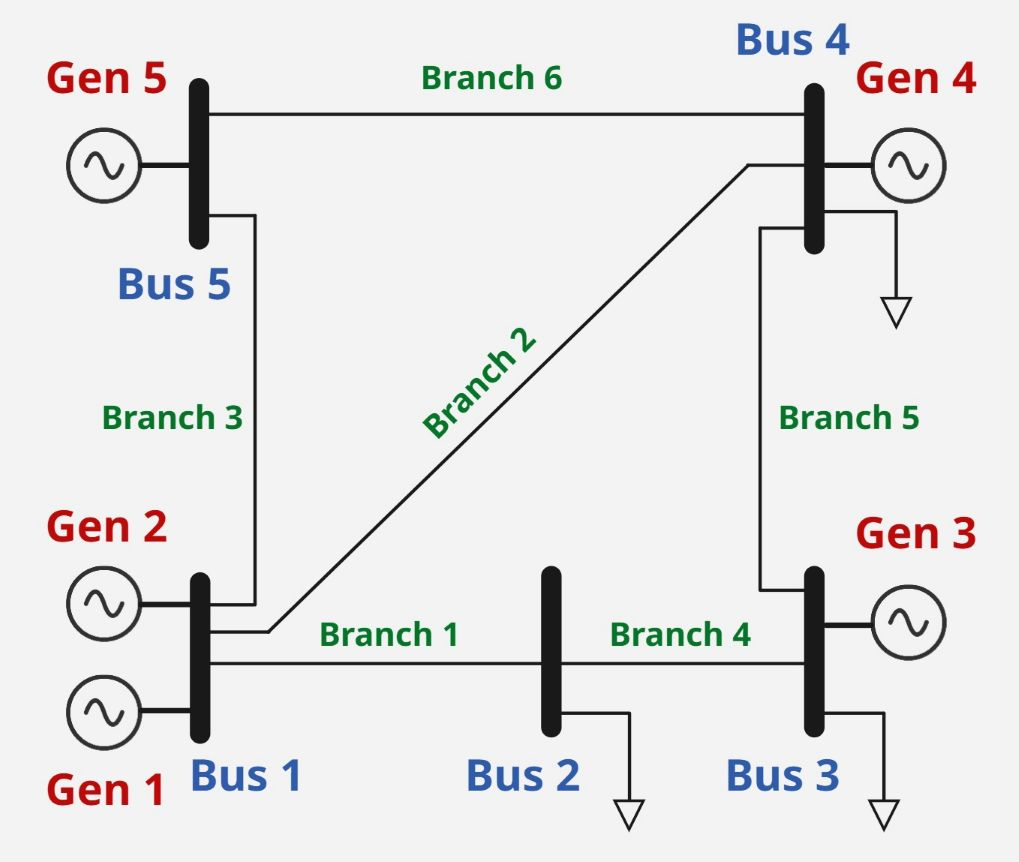

*Figure 1. Five-bus network topology used in the multi-period DC-OPF model.*

Buses are labelled 1 to 5. Base demand is 300 MW at Bus 2, 300 MW at Bus 3 and 400 MW at Bus 4 (1000 MW total). The cheapest generator (Gen 5, \$10/MWh, 600 MW) sits at Bus 5, behind the tightest line, Branch 6 (4 to 5, 240 MW).

**Load profile:** a synthetic daily shape scaled to the base demands, low overnight (0.65 times base at hour 3) and peaking at 1.24 times base (1240 MW) at hour 18.

**Solver:** HiGHS, called through Pyomo.


In [1]:
# Dependencies
!pip install -q pyomo highspy numpy pandas matplotlib

In [2]:
import os, time
import numpy as np
import pandas as pd
import pyomo.environ as pyo
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Optional: set the environment variable FIG_DIR (for example ../images) to save the figures as PNG files
FIG_DIR = os.environ.get("FIG_DIR")
def save(fig, name):
    if FIG_DIR:
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight")

In [3]:
baseMVA = 100
slackBus = 4 # angle reference only, no special dispatch role

# base demand per bus (p.u.)
buses = {1: 0.0, 2: 3.00, 3: 3.00, 4: 4.00, 5: 0.0}

# gens = {id: {bus, cost ($/MWh), Pmin, Pmax (p.u.)}}
gens = {
    1: {"bus": 1, "c": 14.0, "Pmin": 0.0, "Pmax": 0.40},
    2: {"bus": 1, "c": 15.0, "Pmin": 0.0, "Pmax": 1.70},
    3: {"bus": 3, "c": 30.0, "Pmin": 0.0, "Pmax": 5.20},
    4: {"bus": 4, "c": 40.0, "Pmin": 0.0, "Pmax": 2.00},
    5: {"bus": 5, "c": 10.0, "Pmin": 0.0, "Pmax": 6.00},
}

# branches = {id: {from, to, x (p.u.), rate (p.u.)}}
branches = {
    1: {"from": 1, "to": 2, "x": 0.0281, "rate": 4.0},
    2: {"from": 1, "to": 4, "x": 0.0304, "rate": 4.26},
    3: {"from": 1, "to": 5, "x": 0.0064, "rate": 4.26},
    4: {"from": 2, "to": 3, "x": 0.0108, "rate": 4.26},
    5: {"from": 3, "to": 4, "x": 0.0297, "rate": 4.26},
    6: {"from": 4, "to": 5, "x": 0.0297, "rate": 2.4},
}

bus_ids, gen_ids, branch_ids = sorted(buses), sorted(gens), sorted(branches)

bus_to_gen = {i: [g for g in gen_ids if gens[g]["bus"] == i] for i in bus_ids}
bus_to_branch = {i: [b for b in branch_ids if i in (branches[b]["from"], branches[b]["to"])] for i in bus_ids}

def other_end(br, i):
    return branches[br]["to"] if i == branches[br]["from"] else branches[br]["from"]

# synthetic 24-hour load shape (multiplier on base demand)
hours = list(range(24))
load_multiplier = {
    0: 0.72, 1: 0.68, 2: 0.66, 3: 0.65, 4: 0.67, 5: 0.72, 6: 0.82, 7: 0.92,
    8: 0.98, 9: 1.00, 10: 0.96, 11: 0.94, 12: 0.92, 13: 0.93, 14: 0.96, 15: 1.02,
    16: 1.10, 17: 1.18, 18: 1.24, 19: 1.20, 20: 1.10, 21: 1.00, 22: 0.90, 23: 0.80,
}

Pd = {(b, t): buses[b] * load_multiplier[t] for b in bus_ids for t in hours}

total_mw = {t: sum(Pd[b, t] for b in bus_ids) * baseMVA for t in hours}
print(f"Peak demand: {max(total_mw.values()):.0f} MW at hour {max(total_mw, key=total_mw.get)}")
print(f"Minimum demand: {min(total_mw.values()):.0f} MW at hour {min(total_mw, key=total_mw.get)}")

ETA, SOC_MIN_FRAC, SOC_INIT_FRAC = 0.95, 0.10, 0.50

Peak demand: 1240 MW at hour 18
Minimum demand: 650 MW at hour 3


In [4]:
# Network data summary (rating in MW; reactance x in p.u. on the 100 MVA base)
display(pd.DataFrame({
    "bus": [gens[g]["bus"] for g in gen_ids],
    "cost_$/MWh": [gens[g]["c"] for g in gen_ids],
    "Pmax_MW": [gens[g]["Pmax"] * baseMVA for g in gen_ids],
}, index=pd.Index(gen_ids, name="gen")))

display(pd.DataFrame({
    "from-to": [f"{branches[b]['from']}-{branches[b]['to']}" for b in branch_ids],
    "x_pu": [branches[b]["x"] for b in branch_ids],
    "rating_MW": [branches[b]["rate"] * baseMVA for b in branch_ids],
}, index=pd.Index(branch_ids, name="branch")))

,bus,cost_$/MWh,Pmax_MW
gen,,,
1,1,14.0,40.0
2,1,15.0,170.0
3,3,30.0,520.0
4,4,40.0,200.0
5,5,10.0,600.0


,from-to,x_pu,rating_MW
branch,,,
1,1-2,0.0281,400.0
2,1-4,0.0304,426.0
3,1-5,0.0064,426.0
4,2-3,0.0108,426.0
5,3-4,0.0297,426.0
6,4-5,0.0297,240.0


## Battery Terms

Five quantities describe a battery, and they are easy to mix up:

| Term | Symbol, unit | Meaning | Where it enters the model |
|---|---|---|---|
| Power rating | $P$, MW | How fast the battery can charge or discharge | Upper bound on `ch[t]` and `dis[t]` |
| Energy capacity | $E$, MWh | How much energy the battery can store | Upper bound on `soc[t]` |
| State of charge (SOC) | MWh | Energy stored at the end of hour $t$ | Variable `soc[t]` |
| Duration | $E/P$, hours | Time to fill or empty the battery at full power | Not a variable: $E = P \times \text{duration}$ |
| C-rate | $P/E$, 1/hour | The same information as duration, inverted | $1/\text{duration}$, so a 4-hour battery is 0.25C |

**Power is a rate, energy is an amount.** The model uses 1-hour steps, so charging at 50 MW for one hour takes 50 MWh from the grid, of which 47.5 MWh is stored (efficiency 0.95). Power limits how much energy can move in one hour. Energy capacity limits how much can be held in total. A battery can be limited by either: a low $P$ makes it fill too slowly in the few cheap hours, and a low $E$ caps how much energy it can shift in a day.

Section 2.1 changes $E$ with $P = E/4$ (fixed 4-hour duration). Section 2.2 changes $P$ and duration separately, so $E$ changes with them.

**Fixed assumptions**

| Parameter | Value |
|---|---|
| One-way efficiency $\eta$ | 0.95 (round trip about 90%) |
| Minimum SOC | 10% of $E$ |
| Initial SOC | 50% of $E$ |
| Terminal SOC | equal to initial SOC |

The terminal condition stops the optimizer from emptying the battery for free in the last hour. The 50% starting level also limits how much energy can be added during the day, which Section 2.4 tests.


## Model

`solve(bus, P_MW, E_MWh)` builds and solves the 24-hour DC-OPF. Set `bus=None` for the no-battery case. The model minimizes total generation cost subject to:

| | Constraint | In words |
|---|---|---|
| C1 | Nodal power balance | At every bus and hour: generation + battery discharge − battery charge − demand = power flowing out through the branches |
| C2 | Branch thermal limit | DC flow $(\theta_i - \theta_j)/x$ stays within ± the branch rating |
| C3 | Angle reference | The angle at the slack bus is fixed at 0 |
| C4 | SOC dynamics | SOC changes by the energy stored minus the energy delivered each hour |
| C5 | Cyclic SOC | The battery ends the day at its starting SOC |

Each constraint is written for every hour. The dual of C1 at a given bus and hour is the nodal price there (see *Reading Duals in a Multi-Period Model*).

Variable bounds: generators between their minimum and maximum output, $0 \le ch_t, dis_t \le P$ and $0.1E \le soc_t \le E$. The SOC equation (C4) is

$$soc_t = soc_{t-1} + \eta\, ch_t - \frac{1}{\eta}\, dis_t.$$

Charging $ch_t$ stores only $\eta\, ch_t$, and delivering $dis_t$ to the grid removes $dis_t/\eta$ from storage.

The model does not forbid charging and discharging in the same hour. That could only waste energy through the efficiency losses, so the optimizer has no reason to do it; Section 2.1 checks that it never does.


In [5]:
def solve(bus=None, P_MW=0.0, E_MWh=0.0):
    # 24-hour DC-OPF with an optional battery at `bus`.

    m = pyo.ConcreteModel()
    m.has_batt = bus is not None and P_MW > 0 and E_MWh > 0

    # Sets
    m.T = pyo.Set(initialize = hours, ordered = True) # hours 0..23
    m.G = pyo.Set(initialize = gen_ids) # generators
    m.B = pyo.Set(initialize = bus_ids) # buses
    m.BR = pyo.Set(initialize = branch_ids) # branches (lines)

    # Decision Variables
    m.Pg = pyo.Var(m.G, m.T, bounds=lambda m, g, t: (gens[g]["Pmin"], gens[g]["Pmax"]), initialize=0)
    m.theta = pyo.Var(m.B, m.T, bounds=(-np.pi, np.pi), initialize=0)

    if m.has_batt:
        P, E = P_MW / baseMVA, E_MWh / baseMVA # battery size in p.u. (100 MVA base)
        soc_min, soc_init = SOC_MIN_FRAC * E, SOC_INIT_FRAC * E
        m.ch = pyo.Var(m.T, bounds = (0, P)) # charging power
        m.dis = pyo.Var(m.T, bounds = (0, P)) # discharging power
        m.soc = pyo.Var(m.T, bounds = (soc_min, E)) # state of charge (energy stored)

    # Objective
    # Minimize total 24-hour generation cost ($): cost per MWh x MW output, summed over generators and hours
    m.obj = pyo.Objective(
        expr = baseMVA * sum(gens[g]["c"] * m.Pg[g, t] for g in m.G for t in m.T),
        sense = pyo.minimize
    )

    # DC branch flow, in p.u. 
    def branch_flow(m, br, t):
        i, j = branches[br]["from"], branches[br]["to"]
        return (m.theta[i, t] - m.theta[j, t]) / branches[br]["x"]

    # C1. Nodal power balance
    def power_balance(m, i, t):
        generation = sum(m.Pg[g, t] for g in bus_to_gen[i])
        battery = (m.dis[t] - m.ch[t]) if (m.has_batt and i == bus) else 0.0   # only at the battery bus
        flow_out = sum(
            (m.theta[i, t] - m.theta[other_end(br, i), t]) / branches[br]["x"]
                       for br in bus_to_branch[i]
        )
        
        return generation + battery - flow_out - Pd[i, t] == 0
        
    m.c_balance = pyo.Constraint(m.B, m.T, rule=power_balance)

    # C2. Branch thermal limit 
    def line_limit(m, br, t):
        return (-branches[br]["rate"], branch_flow(m, br, t), branches[br]["rate"])
    
    m.c_line_limit = pyo.Constraint(m.BR, m.T, rule=line_limit)

    # C3. Angle reference
    m.c_slack = pyo.Constraint(m.T, rule = lambda m, t: m.theta[slackBus, t] == 0)

    # Battery constraints
    if m.has_batt:
        # C4. State-of-charge dynamics: soc[t] = soc[t-1] + eta*charge[t] - (1/eta)*discharge[t]
        def soc_dynamics(m, t):
            previous = soc_init if t == m.T.first() else m.soc[m.T.prev(t)]
            return m.soc[t] == previous + ETA * m.ch[t] - m.dis[t] / ETA
        
        m.c_soc = pyo.Constraint(m.T, rule=soc_dynamics)

        # C5. Cyclic SOC: the battery must end the day where it started. 
        # Without this, the optimizer would empty the battery in the last hour for a free saving.
        m.c_soc_final = pyo.Constraint(expr=m.soc[m.T.last()] == soc_init)

    # Ask the solver to return dual variables (nodal prices, branch shadow prices, SOC value)
    m.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)

    # Solve
    result = pyo.SolverFactory("highs").solve(m)
    if result.solver.termination_condition != pyo.TerminationCondition.optimal:
        raise RuntimeError(
            f"Solve failed: bus={bus}, P={P_MW}, E={E_MWh}: "
            f"{result.solver.termination_condition}"
        )
    m.flow = branch_flow  # kept so the result helpers can read branch flows
    return m

In [6]:
# result helpers 
def cost(m): return pyo.value(m.obj)

def flows_MW(m, br):
    return np.array([pyo.value(m.flow(m, br, t)) * baseMVA for t in hours])

def schedule(m):
    if not m.has_batt:
        return pd.DataFrame({"hour": hours, "charge_MW": 0.0, "discharge_MW": 0.0, "soc_MWh": np.nan})
    return pd.DataFrame({"hour": hours,
        "charge_MW": [pyo.value(m.ch[t]) * baseMVA for t in hours],
        "discharge_MW": [pyo.value(m.dis[t]) * baseMVA for t in hours],
        "soc_MWh": [pyo.value(m.soc[t]) * baseMVA for t in hours]})

def congested_hours(m, br):
    # hours in which |flow| is within 0.1 MW of the branch limit
    return int((np.abs(flows_MW(m, br)) >= branches[br]["rate"] * baseMVA - 0.1).sum())

def dispatch_MWh(m):
    return {g: sum(pyo.value(m.Pg[g, t]) for t in hours) * baseMVA for g in gen_ids}

def lmp(m):
    # nodal prices ($/MWh): one per bus and hour. Duals are per p.u. of demand, so divide by baseMVA.
    return pd.DataFrame({i: [m.dual[m.c_balance[i, t]] / baseMVA for t in hours] for i in bus_ids},
                        index=pd.Index(hours, name="hour"))

def branch_price(m, br):
    # shadow price of a branch limit ($/MWh per extra MW of rating), one per hour; zero when the branch has slack
    return np.array([abs(m.dual[m.c_line_limit[br, t]]) / baseMVA for t in hours])

def stored_energy_value(m):
    # value of one more MWh in storage ($/MWh), one per hour (the SOC dual; Pyomo reports it with a negative sign here)
    return np.array([-m.dual[m.c_soc[t]] / baseMVA for t in hours])

## Checks

Two checks are used:

1. The baseline cost in hour 9, when demand equals the base load, matches the single-period DC-OPF result ([01_dcopf_pyomo.ipynb](https://github.com/vjkhtw/pjm5-opf/blob/main/notebooks/01_dcopf_pyomo.ipynb)).
2. Branch loading identifies the main network bottlenecks before adding a battery.

In [7]:
base = solve()
base_cost = cost(base)
print(f"No-battery 24-hour cost: ${base_cost:,.2f}")

# check 1: hour 9 (multiplier 1.00) against the single-period DC-OPF result
hour9 = sum(gens[g]["c"] * pyo.value(base.Pg[g, 9]) * baseMVA for g in gen_ids)
print(f"Hour-9 cost: ${hour9:,.2f}/h  (single-period DC-OPF: $17,479.90/h)")
assert abs(hour9 - 17479.90) < 0.01

# check 2: congestion without a battery
cong = pd.DataFrame({
    "branch": branch_ids,
    "from-to": [f"{branches[b]['from']}-{branches[b]['to']}" for b in branch_ids],
    "limit_MW": [branches[b]["rate"] * baseMVA for b in branch_ids],
    "max_loading_%": [np.abs(flows_MW(base, b)).max() / (branches[b]["rate"] * baseMVA) * 100 for b in branch_ids],
    "congested_hours": [congested_hours(base, b) for b in branch_ids],
}).set_index("branch").sort_values("congested_hours", ascending=False)
cong.round(1)

No-battery 24-hour cost: $357,972.81
Hour-9 cost: $17,479.90/h  (single-period DC-OPF: $17,479.90/h)


,from-to,limit_MW,max_loading_%,congested_hours
branch,,,,
6,4-5,240.0,100.0,21
1,1-2,400.0,74.7,0
2,1-4,426.0,45.0,0
3,1-5,426.0,86.1,0
4,2-3,426.0,31.2,0
5,3-4,426.0,30.6,0


Without a battery, Branch 6 (Bus 4 - Bus 5, 240 MW) is at its limit for 21 of 24 hours, and no other branch reaches its limit. The next most loaded branches are Branch 3 (Bus 1 - Bus 5, 86% of its limit at peak) and Branch 1 (Bus 1 - Bus 2, 75%). Branch 6 is the main bottleneck between the cheap generator at Bus 5 and the rest of the network.

## Reading Duals in a Multi-Period Model

A dual is the Lagrange multiplier of a constraint. It tells you how much the optimal cost changes if that constraint is relaxed by one unit.

In the single-period DC-OPF there is one power balance per bus, so one dual per bus: the LMP. Here the balance is written for every bus *and* every hour, so there are 5 × 24 = 120 balance constraints and 120 prices. Prices differ from hour to hour because each hour has its own constraint.

* **LMP at (bus *i*, hour *t*)** is the cost of supplying 1 more MW at bus *i* in hour *t*. Pyomo returns duals per p.u., so they are divided by `baseMVA` to get \$/MWh.
* **Branch shadow price at (branch *b*, hour *t*)** is how much the total cost would fall with 1 MW more rating on branch *b* in hour *t*. It is zero when the branch has slack.

**Without a battery** the hours are independent. The extra MW only changes that hour's dispatch, so the LMP is the change in that hour's cost.

**With a battery** the hours are linked by the SOC equation. The data in the other hours stays the same, but their decisions can change: if the battery stores less overnight, the evening needs more generation. So the LMP is the change in the **whole-day** cost, not just that hour's.

The SOC equation has a dual too, the **stored-energy value**: how much the total cost would fall if the battery held 1 more MWh at that time. It is not an input. The solver computes it, and it ties the battery's decisions to the prices ($\eta = 0.95$):

| Hour type | Rule at the battery's bus | Why |
|---|---|---|
| Charging | LMP $= \eta \times$ value | each MWh bought from the grid stores only $\eta$ MWh |
| Discharging | LMP $=$ value $/\,\eta$ | each MWh delivered removes $1/\eta$ MWh from storage |
| Idle | LMP between the two | neither action pays |

The rules hold in hours where the battery is not at a limit; Section 3.2 shows an example where the value changes because the battery becomes full.

The no-battery nodal prices at three hours (low load, base load, peak) show how congestion appears in the prices:

In [8]:
# No-battery nodal prices at hour 3 (lowest load), hour 9 (base load) and hour 18 (peak)
L0 = lmp(base)
show = L0.loc[[3, 9, 18]].T
show.columns = [f"Hour {t}" for t in show.columns]
show.index.name = "Bus"
show.loc["Branch 6 shadow price"] = [branch_price(base, 6)[t] for t in (3, 9, 18)]
show.style.format("${:,.2f}")

,Hour 3,Hour 9,Hour 18
Bus,,,
1,$15.00,$16.98,$16.99
2,$15.00,$26.38,$26.42
3,$15.00,$30.00,$30.04
4,$15.00,$39.94,$40.00
5,$15.00,$10.00,$10.00
Branch 6 shadow price,$0.00,$62.32,$62.44


In hour 3 every bus has the same price (*\$15*) and Branch 6's shadow price is zero: the line has slack, so the network acts as one market. In hours 9 and 18 Branch 6 is at its limit, its shadow price is about *\$62/MWh*, and the nodal prices separate: Bus 5, behind the line, is at its own generator's cost (*\$10*), and Bus 4, on the load side, is at *\$39.94* to *\$40.00*. A gap between nodal prices is the signature of congestion, and the branch shadow price is the quantity that creates it.

## 1. Siting at a Fixed Size
First the siting question at one size, 50 MW / 200 MWh (a 4-hour battery).

In [9]:
P0, E0 = 50, 200
rows = []
for b in bus_ids:
    m = solve(b, P0, E0) 
    s = schedule(m)
    rows.append({"bus": f"{b}", "total_cost_$": cost(m), "savings_$": base_cost - cost(m),
                 "savings_%": 100 * (base_cost - cost(m)) / base_cost,
                 "charged_MWh": s.charge_MW.sum(), "discharged_MWh": s.discharge_MW.sum(),
                 "branch6_congested_h": congested_hours(m, 6)})
siting = pd.DataFrame(rows).set_index("bus").sort_values("savings_$", ascending=False)
siting.style.format({"total_cost_$": "${:,.2f}", "savings_$": "${:,.2f}", "savings_%": "{:.3f}%",
                     "charged_MWh": "{:.1f}", "discharged_MWh": "{:.1f}"})

,total_cost_$,savings_$,savings_%,charged_MWh,discharged_MWh,branch6_congested_h
bus,,,,,,
4,"$356,901.02","$1,071.79",0.299%,107.5,97.0,24
3,"$357,097.61",$875.21,0.244%,108.6,98.0,24
2,"$357,169.61",$803.20,0.224%,109.3,98.7,24
5,"$357,624.59",$348.22,0.097%,114.9,103.7,23
1,"$357,934.58",$38.24,0.011%,114.8,103.6,21


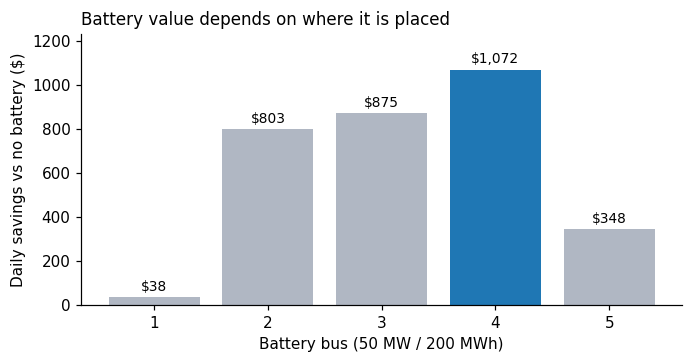

In [10]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
order = siting.sort_index().index
vals = siting.loc[order, "savings_$"]
bars = ax.bar(order, vals, color=["#1f77b4" if v == vals.max() else "#b0b7c3" for v in vals])
ax.bar_label(bars, labels=[f"${v:,.0f}" for v in vals], padding=2, fontsize=9)
ax.set_ylabel("Daily savings vs no battery ($)")
ax.set_xlabel("Battery bus (50 MW / 200 MWh)")
ax.set_title("Battery value depends on where it is placed", loc="left", fontsize=11)
ax.set_ylim(0, vals.max() * 1.15)
fig.tight_layout(); plt.savefig("bess_siting.png"); plt.show()

In [11]:
# no-battery nodal prices: how far does the price at each bus swing over the day?
L0 = lmp(base)
rng = pd.DataFrame({"lowest_LMP_$/MWh": L0.min(), "highest_LMP_$/MWh": L0.max()})
rng["daily_range_$/MWh"] = rng["highest_LMP_$/MWh"] - rng["lowest_LMP_$/MWh"]
rng["battery_savings_$"] = [siting.loc[str(b), "savings_$"] for b in rng.index]
rng.index.name = "bus"
rng.sort_values("daily_range_$/MWh", ascending=False).style.format("{:,.2f}")

,lowest_LMP_$/MWh,highest_LMP_$/MWh,daily_range_$/MWh,battery_savings_$
bus,,,,
4,15.00,40.00,25.00,"1,071.79"
3,15.00,30.04,15.04,875.21
2,15.00,26.42,11.42,803.20
5,10.00,15.00,5.00,348.22
1,15.00,16.99,1.99,38.24


At this size, Bus 4 gives the largest saving (*\$1,071.79* per day, 0.30%), followed by Bus 3 (*\$875.21*), Bus 2 (*\$803.20*), Bus 5 (*\$348.22*) and Bus 1 (*\$38.24*). The order matches the daily range of the no-battery nodal prices (table above): a battery earns by charging when the price at its bus is low and discharging when it is high, so a bus whose price swings more is worth more. Bus 4 swings the most (*\$15* to *\$40*/MWh). It is on the load side of Branch 6 and hosts Gen 4, the most expensive unit (*\$40*/MWh), which sets its price at the evening peak. Section 3 shows how the battery uses this.

Bus 5 is behind Branch 6, so a battery there cannot relieve the bottleneck. It still saves a little by a different route: it charges in hours when Gen 5 (*\$10*/MWh) has spare capacity and discharges in hours 2 to 4, when Gen 5 is at its 600 MW limit, replacing Gen 1 and Gen 2 (*\$14* to *\$15*/MWh). The price difference per MWh moved is small, so this saving levels off early (Section 2.1). Bus 1 has almost no price swing and gives almost nothing.

## 2. Sizing

### 2.1 Energy capacity (4-hour duration)

Energy capacity is swept from 0 to 500 MWh. Power is set to one quarter of the energy capacity, so every case has a 4-hour duration.

In [12]:
t0 = time.time()
Es = list(range(0, 525, 25))
rows = []

for b in bus_ids:
    for E in Es:
        if E == 0:
            rows.append({
                "bus": b, "E_MWh": 0, "P_MW": 0,
                "savings": 0.0, "charged": 0.0,
                "discharged": 0.0, "br6_h": congested_hours(base, 6), "overlap_MW": 0.0
            })
            continue

        m = solve(b, E / 4, E)
        s = schedule(m)

        rows.append({
            "bus": b,
            "E_MWh": E,
            "P_MW": E / 4,
            "savings": base_cost - cost(m),
            "charged": s.charge_MW.sum(),
            "discharged": s.discharge_MW.sum(),
            "br6_h": congested_hours(m, 6),
            # If the battery only charges or only discharges in an hour, one of the two is 0, so the minimum is 0.
            "overlap_MW": float(np.minimum(s.charge_MW, s.discharge_MW).max())
        })

curve = pd.DataFrame(rows)
print(f"{len(curve)} solves in {time.time() - t0:.1f} s")
print(f"Largest charge/discharge overlap in any solve: {curve.overlap_MW.max():.6f} MW")

# Daily operating-cost savings by battery capacity and installation bus
sav = curve.pivot(index="E_MWh", columns="bus", values="savings")
sav.columns = [f"Bus {b}" for b in sav.columns]
sav.index.name = "Battery Energy Capacity (MWh)"
sav.columns.name = "Battery Installation Bus"

display(
    sav.loc[[50, 100, 200, 300, 400, 500]]
    .round(0)
    .style.format("${:,.0f}")
)

105 solves in 6.2 s
Largest charge/discharge overlap in any solve: 0.000000 MW


Battery Installation Bus,Bus 1,Bus 2,Bus 3,Bus 4,Bus 5
Battery Energy Capacity (MWh),,,,,
50,$12,$297,$384,$606,$143
100,$21,$523,$657,$828,$237
200,$38,$803,$875,"$1,072",$348
300,$56,$913,"$1,021","$1,314",$348
400,$73,"$1,023","$1,165","$1,314",$348
500,$91,"$1,132","$1,236","$1,314",$348


The table compares daily operating-cost savings against the no-battery case for each installation location and battery size.

In all 105 solves the battery never charges and discharges in the same hour (largest overlap shown above), so no constraint against it is needed in the model.

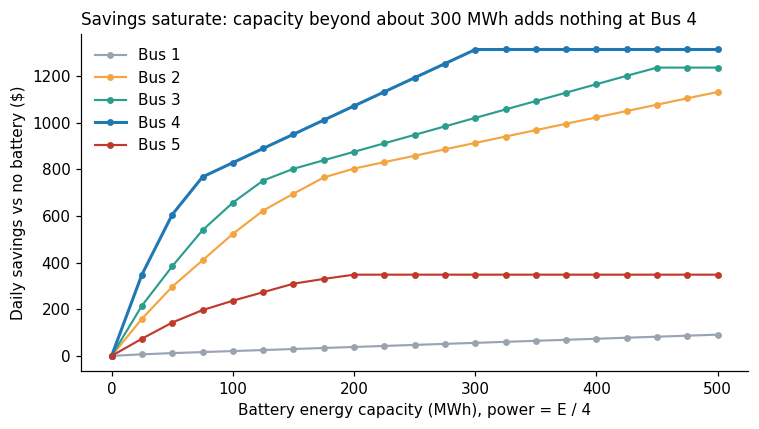

In [13]:
colors = {1: "#9aa3b2", 2: "#f2a541", 3: "#2a9d8f", 4: "#1f77b4", 5: "#c0392b"}
fig, ax = plt.subplots(figsize=(7, 4))
for b in bus_ids:
    d = curve[curve.bus == b]
    ax.plot(d.E_MWh, d.savings, marker="o", ms=3.5, lw=2 if b == 4 else 1.4, color=colors[b], label=f"Bus {b}")
ax.set_xlabel("Battery energy capacity (MWh), power = E / 4")
ax.set_ylabel("Daily savings vs no battery ($)")
ax.set_title("Savings saturate: capacity beyond about 300 MWh adds nothing at Bus 4", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); plt.savefig("bess_sizing_curve.png"); plt.show()

In [14]:
# where does each bus reach 95% of its largest savings in this sweep?
knee = []
for b in bus_ids:
    d = curve[curve.bus == b].set_index("E_MWh").savings
    rising = bool(d.iloc[-1] > d.iloc[-2] + 1)       # still growing by more than $1/day at 500 MWh
    knee.append({
        "bus": f"{b}",
        "max_savings_$": round(d.max()),
        "E_at_95%_of_max_MWh": "not reached (still rising)" if rising else d.index[(d >= 0.95 * d.max()).values][0],
        "still_rising_at_500MWh": rising,
    })
pd.DataFrame(knee).set_index("bus")

,max_savings_$,E_at_95%_of_max_MWh,still_rising_at_500MWh
bus,,,
1,91,not reached (still rising),True
2,1132,not reached (still rising),True
3,1236,425,False
4,1314,275,False
5,348,200,False


At Bus 4, savings increase with energy capacity up to about 300 MWh, then level off at approximately *\$1,314* per day. A 250 MWh battery captures 91% of this maximum and 275 MWh captures 95%.

The other buses behave differently. Bus 3 levels off lower, at *\$1,236* (94% of Bus 4) from about 425 MWh. Bus 2 (*\$1,132*) and Bus 1 (*\$91*) are still rising at 500 MWh, so their maximum is just the end of the sweep and not a true plateau. Bus 5 saves *\$348* and is flat from 200 MWh.

The gap between sites narrows as capacity grows. At 100 MWh, Bus 3 and Bus 2 capture 79% and 63% of Bus 4's saving; at 500 MWh they capture 94% and 86%. Location therefore matters most for small batteries. These results assume each battery starts and ends the day at 50% state of charge, which Section 2.4 tests.

### 2.2 Power rating and duration

Section 2.1 kept the duration at 4 hours, so power and energy moved together. Here power and duration are varied separately, so energy changes with both ($E = P \times \text{duration}$, see [Battery Terms](#Battery-Terms)). Each heatmap cell is one battery design and prints its daily savings and its energy capacity.


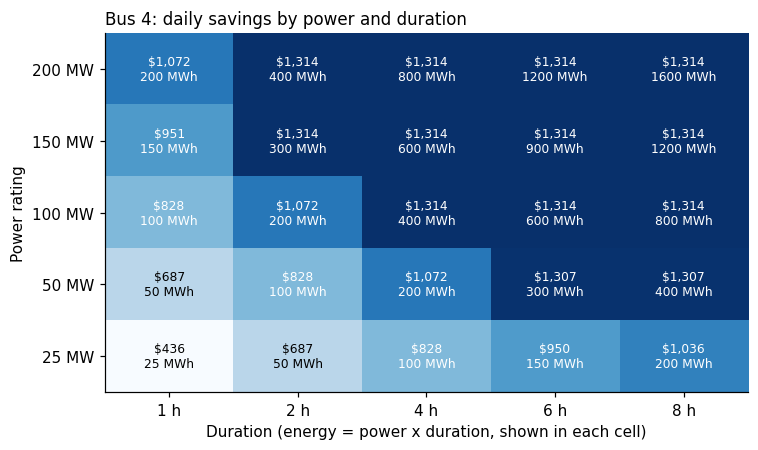

In [15]:
Ps = [25, 50, 100, 150, 200]
Ds = [1, 2, 4, 6, 8]
grid = pd.DataFrame({d: [base_cost - cost(solve(4, p, p * d)) for p in Ps] for d in Ds}, index=Ps)
grid.index.name = "power_MW"; grid.columns.name = "duration_h"

fig, ax = plt.subplots(figsize=(7, 4.2))
im = ax.imshow(grid.values, cmap="Blues", aspect="auto", origin="lower")
ax.set_xticks(range(len(Ds)), [f"{d} h" for d in Ds]); ax.set_yticks(range(len(Ps)), [f"{p} MW" for p in Ps])
for i in range(len(Ps)):
    for j in range(len(Ds)):
        v = grid.values[i, j]
        ax.text(j, i, f"${v:,.0f}\n{Ps[i] * Ds[j]} MWh", ha="center", va="center", fontsize=8, color="white" if v > 0.6 * grid.values.max() else "black")
ax.set_xlabel("Duration (energy = power x duration, shown in each cell)"); ax.set_ylabel("Power rating")
ax.set_title("Bus 4: daily savings by power and duration", loc="left", fontsize=11)
fig.tight_layout(); plt.savefig("bess_power_duration_bus_d.png"); plt.show()

Savings follow the energy capacity shown in each cell. Designs with the same MWh save almost the same amount even when their power ratings differ by a factor of 4 or more: all three 100 MWh designs (25 MW / 4 h, 50 MW / 2 h, 100 MW / 1 h) save *\$828*, and 50 MW / 4 h and 100 MW / 2 h (both 200 MWh) both save *\$1,072*. Raising the power of a 200 MWh battery above 50 MW adds nothing.

Power starts to matter only at very long durations. The 25 MW / 8 h design (also 200 MWh) saves *\$1,036*, 3.4% less. Longer designs at 6 to 8 hours lose between 0.1% and 3.4% relative to a higher-power battery of the same energy. Savings reach their maximum (*\$1,314*) once the design has at least 300 MWh and enough power to charge it in time.

### 2.3 Battery utilization

This section examines how much of the installed battery capacity is actually used. The battery is placed at Bus 4, and its duration is kept fixed at 4 hours. As energy capacity increases from 50 to 500 MWh, power capacity increases proportionally, with $P=E/4$.

The table reports the battery's total daily discharged energy and equivalent full cycles (EFC). EFC is calculated as:

$$
\text{EFC}=\frac{\text{Daily discharged energy (MWh)}}{\text{Battery energy capacity (MWh)}}
$$


In [16]:
d = curve[curve.bus == 4].set_index("E_MWh")
sizes = [100, 200, 250, 300, 400, 500]
tab = pd.DataFrame({
    "power_MW": d.loc[sizes, "P_MW"],
    "daily_savings_$": d.loc[sizes, "savings"],
    "discharged_MWh/day": d.loc[sizes, "discharged"],
    "full_cycles/day": d.loc[sizes, "discharged"] / np.array(sizes),
})
tab.index.name = "Energy capacity (MWh)"
tab.style.format({
    "power_MW": "{:.1f}",
    "daily_savings_$": "${:,.0f}",
    "discharged_MWh/day": "{:.1f}",
    "full_cycles/day": "{:.2f}",
})

,power_MW,daily_savings_$,discharged_MWh/day,full_cycles/day
Energy capacity (MWh),,,,
100,25.0,$828,49.5,0.50
200,50.0,"$1,072",97.0,0.49
250,62.5,"$1,193",120.8,0.48
300,75.0,"$1,314",144.5,0.48
400,100.0,"$1,314",144.6,0.36
500,125.0,"$1,314",144.6,0.29


Daily discharge levels off at about 145 MWh once capacity reaches 300 MWh, since there is no more useful energy to shift. Equivalent full cycles stay near 0.5 per day up to 300 MWh and then fall, to 0.29 at 500 MWh, so larger batteries are used less.

At Bus 4, 50 MW / 200 MWh captures about 82% of the maximum daily saving, while 62.5 MW / 250 MWh captures about 91%. The 75 MW / 300 MWh case reaches the maximum in this sweep. Choosing among these sizes would require battery cost and degradation data, which are not included here.

### 2.4 Sensitivity to initial and terminal SOC

All batteries so far start and end the day at 50% state of charge (SOC), so only half of the capacity can be filled during the day. Here the Bus 4 sizing sweep is repeated with a 10% start, the SOC floor, which leaves most of the capacity available for charging.

In [17]:
# solve() reads SOC_INIT_FRAC each time it is called, so it is changed here and restored afterwards
Es_check = [100, 150, 200, 250, 300, 400]
soc_test = {}
for frac in [0.5, 0.1]:
    SOC_INIT_FRAC = frac
    soc_test[f"{int(frac * 100)}% initial SOC"] = [base_cost - cost(solve(4, E / 4, E)) for E in Es_check]
SOC_INIT_FRAC = 0.5                                   # restore the default

pd.DataFrame(soc_test, index=pd.Index(Es_check, name="Energy capacity (MWh)")).style.format("${:,.0f}")

,50% initial SOC,10% initial SOC
Energy capacity (MWh),,
100,$828,"$1,012"
150,$950,"$1,219"
200,"$1,072","$1,307"
250,"$1,193","$1,314"
300,"$1,314","$1,314"
400,"$1,314","$1,314"


With a 50% initial SOC, the battery has only half of its energy capacity available for charging. Starting at 10% provides more room to store energy, allowing smaller batteries to achieve greater daily savings.

For example, a 100 MWh battery saves *\$828* per day with a 50% initial SOC, compared with *\$1,012* with a 10% initial SOC. At 200 MWh the values are *\$1,072* and *\$1,307*. With a 10% start, savings reach the maximum of *\$1,314* at 250 MWh; with a 50% start, the same maximum is reached at 300 MWh.

The maximum daily saving is unchanged, but the battery capacity needed to reach it depends on the initial SOC. Therefore, the sizing results in this notebook are conditional on the assumed 50% initial SOC.

## 3. Battery Operation at Bus 4

This section examines the 50 MW / 200 MWh battery at Bus 4: first its schedule and the generators it displaces (3.1), then the nodal prices and the Branch 6 shadow price that explain the schedule (3.2).

### 3.1 Schedule and Generation Shifts

In [18]:
m_d = solve(4, 50, 200)
chg = {g: dispatch_MWh(m_d)[g] - dispatch_MWh(base)[g] for g in gen_ids}
pd.DataFrame({"gen": gen_ids, "bus": [gens[g]["bus"] for g in gen_ids], "cost_$/MWh": [gens[g]["c"] for g in gen_ids],
              "daily_change_MWh": [chg[g] for g in gen_ids]}).set_index("gen").round(1)

,bus,cost_$/MWh,daily_change_MWh
gen,,,
1,1,14.0,0.0
2,1,15.0,346.5
3,3,30.0,-28.4
4,4,40.0,-78.0
5,5,10.0,-229.6


The table shows how installing a 50 MW / 200 MWh battery at Bus 4 changes each generator's total daily energy production compared with the no-battery case. Positive values indicate increased generation, while negative values indicate reduced generation. The chart below shows when the battery charges and discharges.

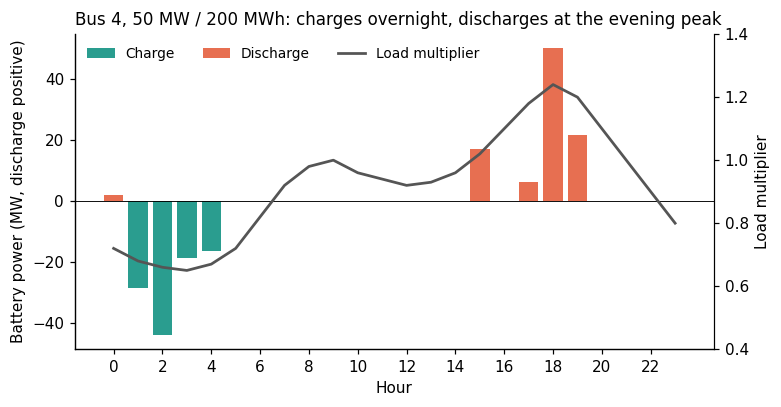

Branch 6 congested hours: 21 without a battery, 24 with it


In [19]:
s = schedule(m_d)
fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.bar(s.hour, -s.charge_MW, color="#2a9d8f", label="Charge")
ax.bar(s.hour, s.discharge_MW, color="#e76f51", label="Discharge")
ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("Hour"); ax.set_ylabel("Battery power (MW, discharge positive)")
ax.set_xticks(range(0, 24, 2))
ax2 = ax.twinx(); ax2.spines["right"].set_visible(True)
ax2.plot(hours, [load_multiplier[t] for t in hours], color="#555555", lw=1.8, label="Load multiplier")
ax2.set_ylabel("Load multiplier"); ax2.set_ylim(0.4, 1.4)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper left", ncol=3, fontsize=9)
ax.set_title("Bus 4, 50 MW / 200 MWh: charges overnight, discharges at the evening peak", loc="left", fontsize=11)
fig.tight_layout(); plt.savefig("bess_schedule_bus_4.png"); plt.show()
print(f"Branch 6 congested hours: {congested_hours(base, 6)} without a battery, {congested_hours(m_d, 6)} with it")

In [20]:
# Detailed schedule
s = schedule(m_d)
hourly = pd.DataFrame({
    "charge_MW": s.charge_MW,
    "discharge_MW": s.discharge_MW,
    "soc_MWh": s.soc_MWh,
    "Gen1_base_MW": [pyo.value(base.Pg[1, t]) * baseMVA for t in hours],
    "Gen1_batt_MW": [pyo.value(m_d.Pg[1, t]) * baseMVA for t in hours],
    "Gen2_base_MW": [pyo.value(base.Pg[2, t]) * baseMVA for t in hours],
    "Gen2_batt_MW": [pyo.value(m_d.Pg[2, t]) * baseMVA for t in hours],
    "Gen3_base_MW": [pyo.value(base.Pg[3, t]) * baseMVA for t in hours],
    "Gen3_batt_MW": [pyo.value(m_d.Pg[3, t]) * baseMVA for t in hours],
    "Gen4_base_MW": [pyo.value(base.Pg[4, t]) * baseMVA for t in hours],
    "Gen4_batt_MW": [pyo.value(m_d.Pg[4, t]) * baseMVA for t in hours],
    "Gen5_base_MW": [pyo.value(base.Pg[5, t]) * baseMVA for t in hours],
    "Gen5_batt_MW": [pyo.value(m_d.Pg[5, t]) * baseMVA for t in hours],
    "Br6_base_MW": np.abs(flows_MW(base, 6)),
    "Br6_batt_MW": np.abs(flows_MW(m_d, 6)),
}, index=pd.Index(hours, name="hour"))
hourly.round(1)

,charge_MW,discharge_MW,soc_MWh,Gen1_base_MW,Gen1_batt_MW,Gen2_base_MW,Gen2_batt_MW,Gen3_base_MW,Gen3_batt_MW,Gen4_base_MW,Gen4_batt_MW,Gen5_base_MW,Gen5_batt_MW,Br6_base_MW,Br6_batt_MW
hour,,,,,,,,,,,,,,,
0,0.0,2.0,97.9,40.0,40.0,170.0,170.0,3.0,0.0,0.0,0.0,507.0,508.0,240.0,240.0
1,28.6,0.0,125.0,40.0,40.0,47.4,170.0,0.0,0.0,0.0,0.0,592.6,498.6,240.0,240.0
2,43.9,0.0,166.7,40.0,40.0,20.0,170.0,0.0,0.0,0.0,0.0,600.0,493.9,235.7,240.0
3,18.6,0.0,184.3,40.0,40.0,10.0,28.6,0.0,0.0,0.0,0.0,600.0,600.0,233.2,240.0
4,16.5,0.0,200.0,40.0,40.0,30.0,85.3,0.0,0.0,0.0,0.0,600.0,561.2,238.3,240.0
5,0.0,-0.0,200.0,40.0,40.0,170.0,170.0,3.0,3.0,0.0,0.0,507.0,507.0,240.0,240.0
6,0.0,-0.0,200.0,40.0,40.0,170.0,170.0,117.5,117.5,0.0,0.0,492.5,492.5,240.0,240.0
7,0.0,0.0,200.0,40.0,40.0,170.0,170.0,231.9,231.9,0.0,0.0,478.1,478.1,240.0,240.0
8,0.0,0.0,200.0,40.0,40.0,170.0,170.0,300.6,300.6,0.0,0.0,469.4,469.4,240.0,240.0


The battery charges overnight in hours 1 to 4 and discharges in the late afternoon and evening (hours 15 and 17 to 19), including a small 2 MW discharge in hour 0 from its starting charge. The hourly table shows the schedule next to the units and the line that change.

Compared with the baseline, generation from Gen 4 (−78.0 MWh) and Gen 3 (−28.4 MWh), the two most expensive units, falls. Gen 2 (*\$15*/MWh) increases by 346.5 MWh, because it supplies the overnight charging. Gen 5, the cheapest unit, produces 229.6 MWh less, which is explained in Section 3.2.

Branch 6 is at its thermal limit for 24 hours with the battery, compared with 21 without it. In hours 2 to 4 the line has some slack without a battery (233 to 238 MW against the 240 MW limit), and charging at Bus 4 uses it up. Whether this relieves the congestion is a question about prices, taken up next.

The schedule is determined by generator costs and network limits, not just by the demand peak.

### 3.2 Prices and Branch 6 Congestion

The duals give the price signal behind this schedule. The figure compares the nodal prices at Bus 4 and Bus 5 and the Branch 6 shadow price with and without the battery. Teal shading marks charging hours and orange marks discharging hours.

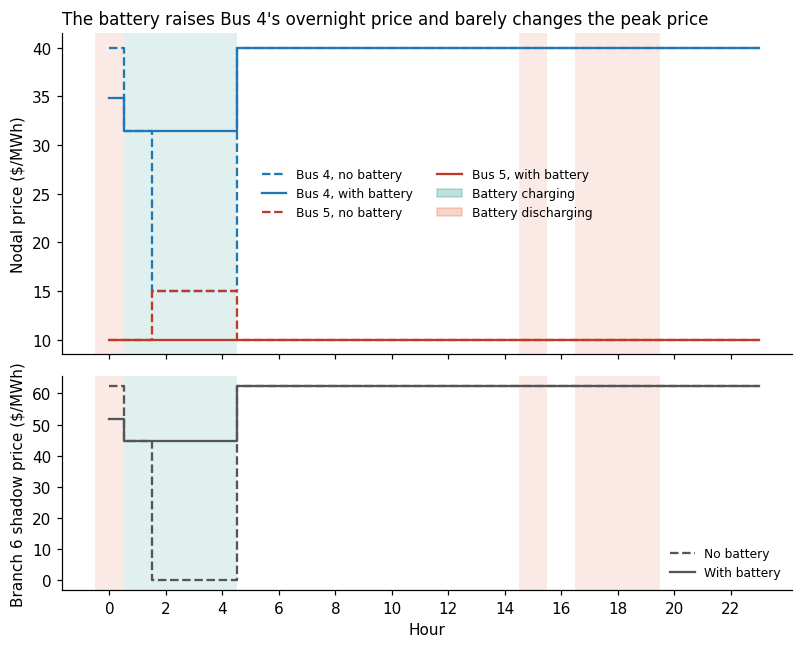

In [21]:
L_b, L_d = lmp(base), lmp(m_d)
mu_b, mu_d = branch_price(base, 6), branch_price(m_d, 6)
s_d = schedule(m_d)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.4, 6), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
ax1.step(hours, L_b[4], where="mid", color="#1f77b4", ls="--", label="Bus 4, no battery")
ax1.step(hours, L_d[4], where="mid", color="#1f77b4", label="Bus 4, with battery")
ax1.step(hours, L_b[5], where="mid", color="#c0392b", ls="--", label="Bus 5, no battery")
ax1.step(hours, L_d[5], where="mid", color="#c0392b", label="Bus 5, with battery")
ax1.set_ylabel("Nodal price ($/MWh)")
from matplotlib.patches import Patch
h, l = ax1.get_legend_handles_labels()
h += [Patch(color="#2a9d8f", alpha=0.3), Patch(color="#e76f51", alpha=0.3)]
l += ["Battery charging", "Battery discharging"]
ax1.legend(h, l, frameon=False, ncol=2, fontsize=8, loc="center")
ax1.set_title("The battery raises Bus 4's overnight price and barely changes the peak price", loc="left", fontsize=11)

ax2.step(hours, mu_b, where="mid", color="#555555", ls="--", label="No battery")
ax2.step(hours, mu_d, where="mid", color="#555555", label="With battery")
ax2.set_ylabel("Branch 6 shadow price ($/MWh)"); ax2.set_xlabel("Hour")
ax2.set_xticks(range(0, 24, 2)); ax2.legend(frameon=False, fontsize=8, loc="lower right")

for ax in (ax1, ax2):
    for t in hours:
        if s_d.charge_MW[t] > 0.5: ax.axvspan(t - 0.5, t + 0.5, color="#2a9d8f", alpha=0.15, lw=0)
        if s_d.discharge_MW[t] > 0.5: ax.axvspan(t - 0.5, t + 0.5, color="#e76f51", alpha=0.15, lw=0)
fig.tight_layout(); plt.savefig("bess_prices_bus_4.png"); plt.show()

In [22]:
# Price rule check at the hours where the battery acts (value = stored-energy value, $/MWh)
value = stored_energy_value(m_d)
rule = pd.DataFrame({
    "charge_MW": s_d.charge_MW, "discharge_MW": s_d.discharge_MW,
    "LMP4_no_batt": L_b[4], "LMP4_batt": L_d[4],
    "value": value, "eta*value": ETA * value, "value/eta": value / ETA,
    "Br6_price_no_batt": mu_b, "Br6_price_batt": mu_d,
}, index=pd.Index(hours, name="hour")).loc[[0, 1, 2, 3, 4, 15, 17, 18, 19]]
rule.style.format("{:.2f}")

,charge_MW,discharge_MW,LMP4_no_batt,LMP4_batt,value,eta*value,value/eta,Br6_price_no_batt,Br6_price_batt
hour,,,,,,,,,
0,0.00,2.00,39.94,34.86,33.11,31.46,34.86,62.32,51.73
1,28.58,0.00,31.46,31.46,33.11,31.46,34.86,44.66,44.66
2,43.87,0.00,15.00,31.46,33.11,31.46,34.86,0.00,44.66
3,18.55,0.00,15.00,31.46,33.11,31.46,34.86,0.00,44.66
4,16.49,0.00,15.00,31.46,33.11,31.46,34.86,0.00,44.66
15,0.00,16.98,39.94,39.94,37.95,36.05,39.94,62.32,62.32
17,0.00,6.36,40.00,39.94,37.95,36.05,39.94,62.44,62.32
18,0.00,50.00,40.00,40.00,37.95,36.05,39.94,62.44,62.44
19,0.00,21.65,40.00,39.94,37.95,36.05,39.94,62.44,62.32


**Branch 6 is not relieved.** Its shadow price is essentially unchanged at the peak (about *\$62*/MWh). In hours 2 to 4 it rises from zero to about *\$45*/MWh, because charging at Bus 4 fills the slack the line had. The battery adds overnight congestion rather than removing congestion.

**The overnight price is pulled up and flattened.** Without a battery, Bus 4 is at *\$31.46* in hour 1 and at *\$15* in hours 2 to 4. Charging adds load until the price is *\$31.46* in all four hours, which is the price rule: *\$31.46* = 0.95 × the stored-energy value of *\$33.11*/MWh. Hour 0, where the battery gives back 2 MW, follows the discharge rule instead: *\$34.86* = *\$33.11* / 0.95.

**Gen 5 backs off because the line strands it.** With Branch 6 full, extra load at Bus 4 cannot be served by cheap Gen 5, so Gen 2 supplies it. In hours 1 to 4 the Bus 5 price falls to Gen 5's own cost (*\$10*) while Bus 4 rises to *\$31.46*, and Gen 5 produces 239 MWh less in hours 1, 2 and 4 (it produces 8.4 MWh more in hour 15). This is the 229.6 MWh reduction in Section 3.1.

**The peak price barely moves.** The battery displaces Gen 4 in the evening (and Gen 3 in hour 15), but Bus 4 only goes from *\$40.00* to *\$39.94* in hours 17 and 19 and stays at *\$40.00* in hour 18, where Gen 4 is still running and still sets the price. The battery shifts energy to the peak without lowering the peak price. Hours 15, 17 and 19 follow the discharge rule (*\$37.95* / 0.95 = *\$39.94*); hour 18 is at the 50 MW limit, which is why its price sits slightly above that.

The stored-energy value jumps from *\$33.11* to *\$37.95* between hours 4 and 5. The battery reaches its 200 MWh limit in hour 4 and stays full until hour 15, so the energy limit is what separates the two values.

## Conclusion

Battery location has a strong effect on savings in this network. Bus 4 performs best (*\$1,071.79* per day at 50 MW / 200 MWh, 0.30%) because it is on the load side of the main bottleneck, Branch 6, and has the widest daily price range (*\$15* to *\$40*/MWh). At Bus 4, savings level off at about *\$1,314* per day once capacity reaches 300 MWh, and energy capacity, not power rating, limits the savings as long as the power rating is at least a quarter of the energy capacity. A 50 MW / 200 MWh battery captures about 82% of the maximum, a 250 MWh battery about 91% and a 275 MWh battery about 95%. The saturation point assumes a 50% initial and terminal state of charge; with both set to 10%, it falls to about 250 MWh.

The battery charges during low-cost overnight hours and discharges in the evening, reducing the output required from the more expensive Gen 3 and Gen 4. It does not relieve Branch 6: the line's shadow price is essentially unchanged at the peak, and overnight charging makes the line bind in hours when it had slack.
